<a href="https://colab.research.google.com/github/kdrhanegrilmez/mL-Notebooks/blob/main/Kadirhan_E%C4%9Frilmez_YZM711_Sinav.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# YZM711 – Python ile Veri Analizi Uygulamalı Sınavı
## Orman Yangını Veri Seti Analizi
## Kadirhan Eğrilmez

## Soru 1 – Veri Yükleme ve Ortam Kurulumu
Bu bölümde analiz için gerekli olan temel Python kütüphaneleri (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`) ortama import edilmiş ve `OrmanYangini.csv` veri seti okunarak ilk 5 satırı ekrana bastırılmıştır.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings('ignore')

# turkce karakter destegi
plt.rcParams['font.family'] = 'DejaVu Sans'

In [ ]:
# veri setini oku
df = pd.read_csv("OrmanYangini.csv")

# ilk 5 satir
df.head()

,Target,aspect,windspeed_,wind_direc,vci_drough,temperatre,solarrad_R,slope_R,SAVI_R,pressure_R,...,humidity_R,forest_cov,EVI_R,ESI_Drough,elevation_,ds_buildin,dist_to_ri,curvatureR,canopy_hei,BII_R
0,0,204.7750,4.12460,135.541,6.0,14.4,1612.94,9.36576,0.342161,986.803,...,61.6445,1.0,0.336709,3.16234,372.0,7007.19,2208.09,0.273850,3.0,0.593721
1,0,178.3860,4.84216,134.830,6.0,10.8,1659.70,46.46190,0.333365,987.800,...,61.6309,1.0,0.259331,2.34528,1122.0,9136.25,2466.50,1.026940,0.0,0.929234
2,0,82.9716,4.37131,135.969,6.0,13.9,1544.28,48.11330,0.222559,986.895,...,61.6510,0.0,0.288586,3.16234,616.0,10032.80,1789.34,1.369250,2.0,0.717178
3,0,221.1350,5.57610,135.557,6.0,11.9,1565.83,34.30620,0.299925,987.169,...,61.6440,1.0,0.298848,1.38365,901.0,12237.50,2197.15,0.616162,5.0,0.778189
4,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,3.16234,NaN,NaN,NaN,NaN,NaN,NaN


## Soru 2 – Veri Setini Tanıma
Veri setinin boyutsal yapısı, içerdiği sütunlar, veri tipleri ve temel istatistiksel özetleri çıkarılmıştır

In [ ]:
# veri setinin boyutu
print("Veri seti boyutu (satir, sutun):", df.shape)

print("\n--- Sutun Isimleri ---")
print(df.columns.tolist())

print("\n--- Veri Tipleri ---")
print(df.dtypes)

Veri seti boyutu (satir, sutun): (7144, 27)

--- Sutun Isimleri ---
['Target', 'aspect', 'windspeed_', 'wind_direc', 'vci_drough', 'temperatre', 'solarrad_R', 'slope_R', 'SAVI_R', 'pressure_R', 'precipitat', 'Population', 'PET_R', 'Ndvi_R', 'NDMI_R', 'lst_R', 'land_use_R', 'humidity_R', 'forest_cov', 'EVI_R', 'ESI_Drough', 'elevation_', 'ds_buildin', 'dist_to_ri', 'curvatureR', 'canopy_hei', 'BII_R']

--- Veri Tipleri ---
Target          int64
aspect        float64
windspeed_    float64
wind_direc    float64
vci_drough    float64
temperatre    float64
solarrad_R    float64
slope_R       float64
SAVI_R        float64
pressure_R    float64
precipitat    float64
Population    float64
PET_R         float64
Ndvi_R        float64
NDMI_R        float64
lst_R         float64
land_use_R    float64
humidity_R    float64
forest_cov    float64
EVI_R         float64
ESI_Drough    float64
elevation_    float64
ds_buildin    float64
dist_to_ri    float64
curvatureR    float64
canopy_hei    float64
BI

In [ ]:
# detayli bilgi
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7144 entries, 0 to 7143
Data columns (total 27 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Target      7144 non-null   int64  
 1   aspect      7115 non-null   float64
 2   windspeed_  7097 non-null   float64
 3   wind_direc  7114 non-null   float64
 4   vci_drough  7069 non-null   float64
 5   temperatre  7075 non-null   float64
 6   solarrad_R  7108 non-null   float64
 7   slope_R     7114 non-null   float64
 8   SAVI_R      7112 non-null   float64
 9   pressure_R  7114 non-null   float64
 10  precipitat  7114 non-null   float64
 11  Population  7096 non-null   float64
 12  PET_R       6121 non-null   float64
 13  Ndvi_R      7104 non-null   float64
 14  NDMI_R      7113 non-null   float64
 15  lst_R       7081 non-null   float64
 16  land_use_R  7111 non-null   float64
 17  humidity_R  7114 non-null   float64
 18  forest_cov  7111 non-null   float64
 19  EVI_R       7103 non-null  

In [ ]:
# istatistiksel ozet
df.describe()

,Target,aspect,windspeed_,wind_direc,vci_drough,temperatre,solarrad_R,slope_R,SAVI_R,pressure_R,...,humidity_R,forest_cov,EVI_R,ESI_Drough,elevation_,ds_buildin,dist_to_ri,curvatureR,canopy_hei,BII_R
count,7144.000000,7115.000000,7097.000000,7114.000000,7069.000000,7075.000000,7108.000000,7114.000000,7112.000000,7114.000000,...,7114.000000,7111.000000,7103.000000,6990.000000,7114.000000,7047.000000,7110.000000,7114.000000,7097.000000,7094.000000
mean,0.552072,179.712369,3.497625,124.444245,4.805347,17.200071,1857.310310,14.933108,0.237066,1000.990712,...,61.508446,0.395303,0.250931,1.824560,217.696373,2512.944148,2869.905720,0.013396,1.545724,0.546170
std,0.497316,101.678031,1.280017,19.134328,0.906350,1.532295,75.905062,15.011116,0.106095,6.481118,...,0.267691,0.488950,0.087556,0.828246,277.558571,2259.584639,2817.138354,0.516330,2.589911,0.180541
min,0.000000,-1.000000,0.553982,42.048600,0.000000,7.600000,1307.960000,0.000000,-0.279034,969.085000,...,60.257400,0.000000,-0.064312,-0.383594,0.000000,0.000000,0.000000,-2.943890,0.000000,0.178455
25%,0.000000,92.726300,2.604380,111.048500,4.000000,16.800000,1820.770000,3.729130,0.176806,998.093500,...,61.288925,0.000000,0.206728,1.335540,28.000000,1566.850000,769.133000,-0.205387,0.000000,0.396675
50%,1.000000,180.000000,3.269340,125.847000,5.000000,17.800000,1882.130000,8.885140,0.257964,1002.800000,...,61.604600,0.000000,0.276360,1.894790,108.000000,2215.870000,1897.500000,0.000000,0.000000,0.505574
75%,1.000000,266.903500,4.209240,138.299000,5.000000,18.200000,1910.620000,22.495200,0.314881,1005.290000,...,61.705875,1.000000,0.312371,2.345280,287.000000,3503.590000,3839.010000,0.205387,2.000000,0.699816
max,1.000000,359.433000,13.099400,211.206000,7.000000,19.200000,2000.470000,102.276000,0.532136,1010.980000,...,61.997600,1.000000,0.476436,3.500000,1855.000000,15668.500000,16523.200000,3.217730,18.000000,0.929651


## Soru 3 – Eksik Veri Analizi
Veri setindeki her bir değişken için eksik (NaN) değerlerin sayısı ve yüzdesel oranları hesaplanmıştır. Eksik verilerin veri seti içindeki dağılımını daha net görebilmek amacıyla eksik değer sayıları ve eksik değer yüzdeleri grafikleri oluşturulmuştur

In [ ]:
# her sutundaki eksik deger sayisi
eksik_sayisi = df.isnull().sum()
eksik_yuzde = (df.isnull().sum() / len(df)) * 100

eksik_tablo = pd.DataFrame({
    'Eksik Deger Sayisi': eksik_sayisi,
    'Eksik Deger Yuzdesi (%)': eksik_yuzde.round(2)
})

# sadece eksik degeri olan sutunlari goster
eksik_tablo = eksik_tablo[eksik_tablo['Eksik Deger Sayisi'] > 0]
eksik_tablo = eksik_tablo.sort_values('Eksik Deger Sayisi', ascending=False)
print(eksik_tablo)

            Eksik Deger Sayisi  Eksik Deger Yuzdesi (%)
PET_R                     1023                    14.32
ESI_Drough                 154                     2.16
ds_buildin                  97                     1.36
vci_drough                  75                     1.05
temperatre                  69                     0.97
lst_R                       63                     0.88
BII_R                       50                     0.70
Population                  48                     0.67
windspeed_                  47                     0.66
canopy_hei                  47                     0.66
EVI_R                       41                     0.57
Ndvi_R                      40                     0.56
solarrad_R                  36                     0.50
dist_to_ri                  34                     0.48
land_use_R                  33                     0.46
forest_cov                  33                     0.46
SAVI_R                      32                  

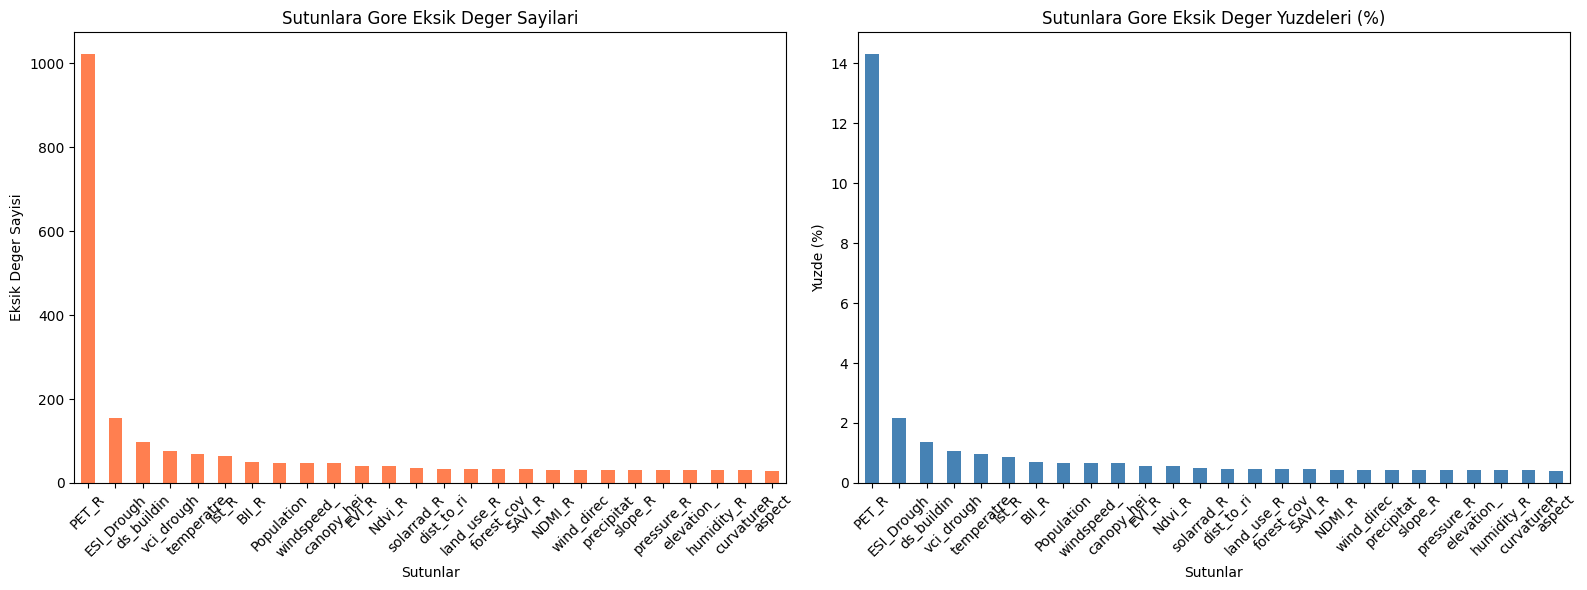

In [ ]:
# eksik verilerin gorsellestirilmesi
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# bar grafik - eksik deger sayilari
eksik_tablo['Eksik Deger Sayisi'].plot(kind='bar', ax=axes[0], color='coral')
axes[0].set_title('Sutunlara Gore Eksik Deger Sayilari')
axes[0].set_xlabel('Sutunlar')
axes[0].set_ylabel('Eksik Deger Sayisi')
axes[0].tick_params(axis='x', rotation=45)

# bar grafik - eksik deger yuzdeleri
eksik_tablo['Eksik Deger Yuzdesi (%)'].plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('Sutunlara Gore Eksik Deger Yuzdeleri (%)')
axes[1].set_xlabel('Sutunlar')
axes[1].set_ylabel('Yuzde (%)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Soru 4 – Eksik Veri Yönetimi
Eksik verilerin çözümü için üç farklı yöntem test edilmiştir:
1. **Silme Yöntemi:** Eksik veri içeren satırların tamamen veri setinden çıkarılması.
2. **Merkezi Eğilim Ölçüleri ile Doldurma:** Eksik değerlerin, ilgili sütunun ortalama veya medyan değerleri ile doldurulması.
3. **Lineer İnterpolasyon:** Zaman serisi veya ardışık veri yapısına uygun olarak eksik noktaların matematiksel interpolasyon ile tahmin edilmesi.

In [ ]:
# Yontem 1: Eksik deger iceren satirlari silme
df_silme = df.dropna()
print("Orijinal veri seti boyutu:", df.shape)
print("Satirlar silindikten sonra:", df_silme.shape)
print("Silinen satir sayisi:", df.shape[0] - df_silme.shape[0])

Orijinal veri seti boyutu: (7144, 27)
Satirlar silindikten sonra: (5930, 27)
Silinen satir sayisi: 1214


In [ ]:
# Yontem 2: Ortalama ve medyan ile doldurma
sayisal_sutunlar = df.select_dtypes(include=[np.number]).columns

# ortalama ile doldurma
df_ortalama = df.copy()
for col in sayisal_sutunlar:
    df_ortalama[col].fillna(df_ortalama[col].mean(), inplace=True)

print("Ortalama ile doldurma sonrasi eksik deger sayisi:", df_ortalama.isnull().sum().sum())

# medyan ile doldurma
df_medyan = df.copy()
for col in sayisal_sutunlar:
    df_medyan[col].fillna(df_medyan[col].median(), inplace=True)

print("Medyan ile doldurma sonrasi eksik deger sayisi:", df_medyan.isnull().sum().sum())

Ortalama ile doldurma sonrasi eksik deger sayisi: 0
Medyan ile doldurma sonrasi eksik deger sayisi: 0


In [ ]:
# Yontem 3: Lineer interpolasyon ile doldurma
df_interpolasyon = df.copy()
for col in sayisal_sutunlar:
    df_interpolasyon[col] = df_interpolasyon[col].interpolate(method='linear')

print("Lineer interpolasyon sonrasi eksik deger sayisi:", df_interpolasyon.isnull().sum().sum())

# devam eden analizler icin medyan ile doldurulmus veriyi kullanacagiz
# medyan aykiri degerlere karsi daha direncli oldugu icin tercih edildi
df_temiz = df_medyan.copy()

Lineer interpolasyon sonrasi eksik deger sayisi: 0


## Soru 5 – Aykırı Değer Analizi (15 Puan)
**Yöntem Karşılaştırması:**
* **Boxplot:** Görsel olarak medyan, çeyreklikler ve aykırı noktaları hızlıca tespit etmemizi sağlar.
* **IQR:** Çeyrekler açıklığını (Q3-Q1) kullanır. Normal dağılım göstermeyen veya çarpık verilerde daha etkilidir.
* **Z-Score:** Verinin normal dağıldığı varsayımıyla çalışır. Ortalama ve standart sapmayı kullanır, ekstrem uç değerlere karşı hassastır.


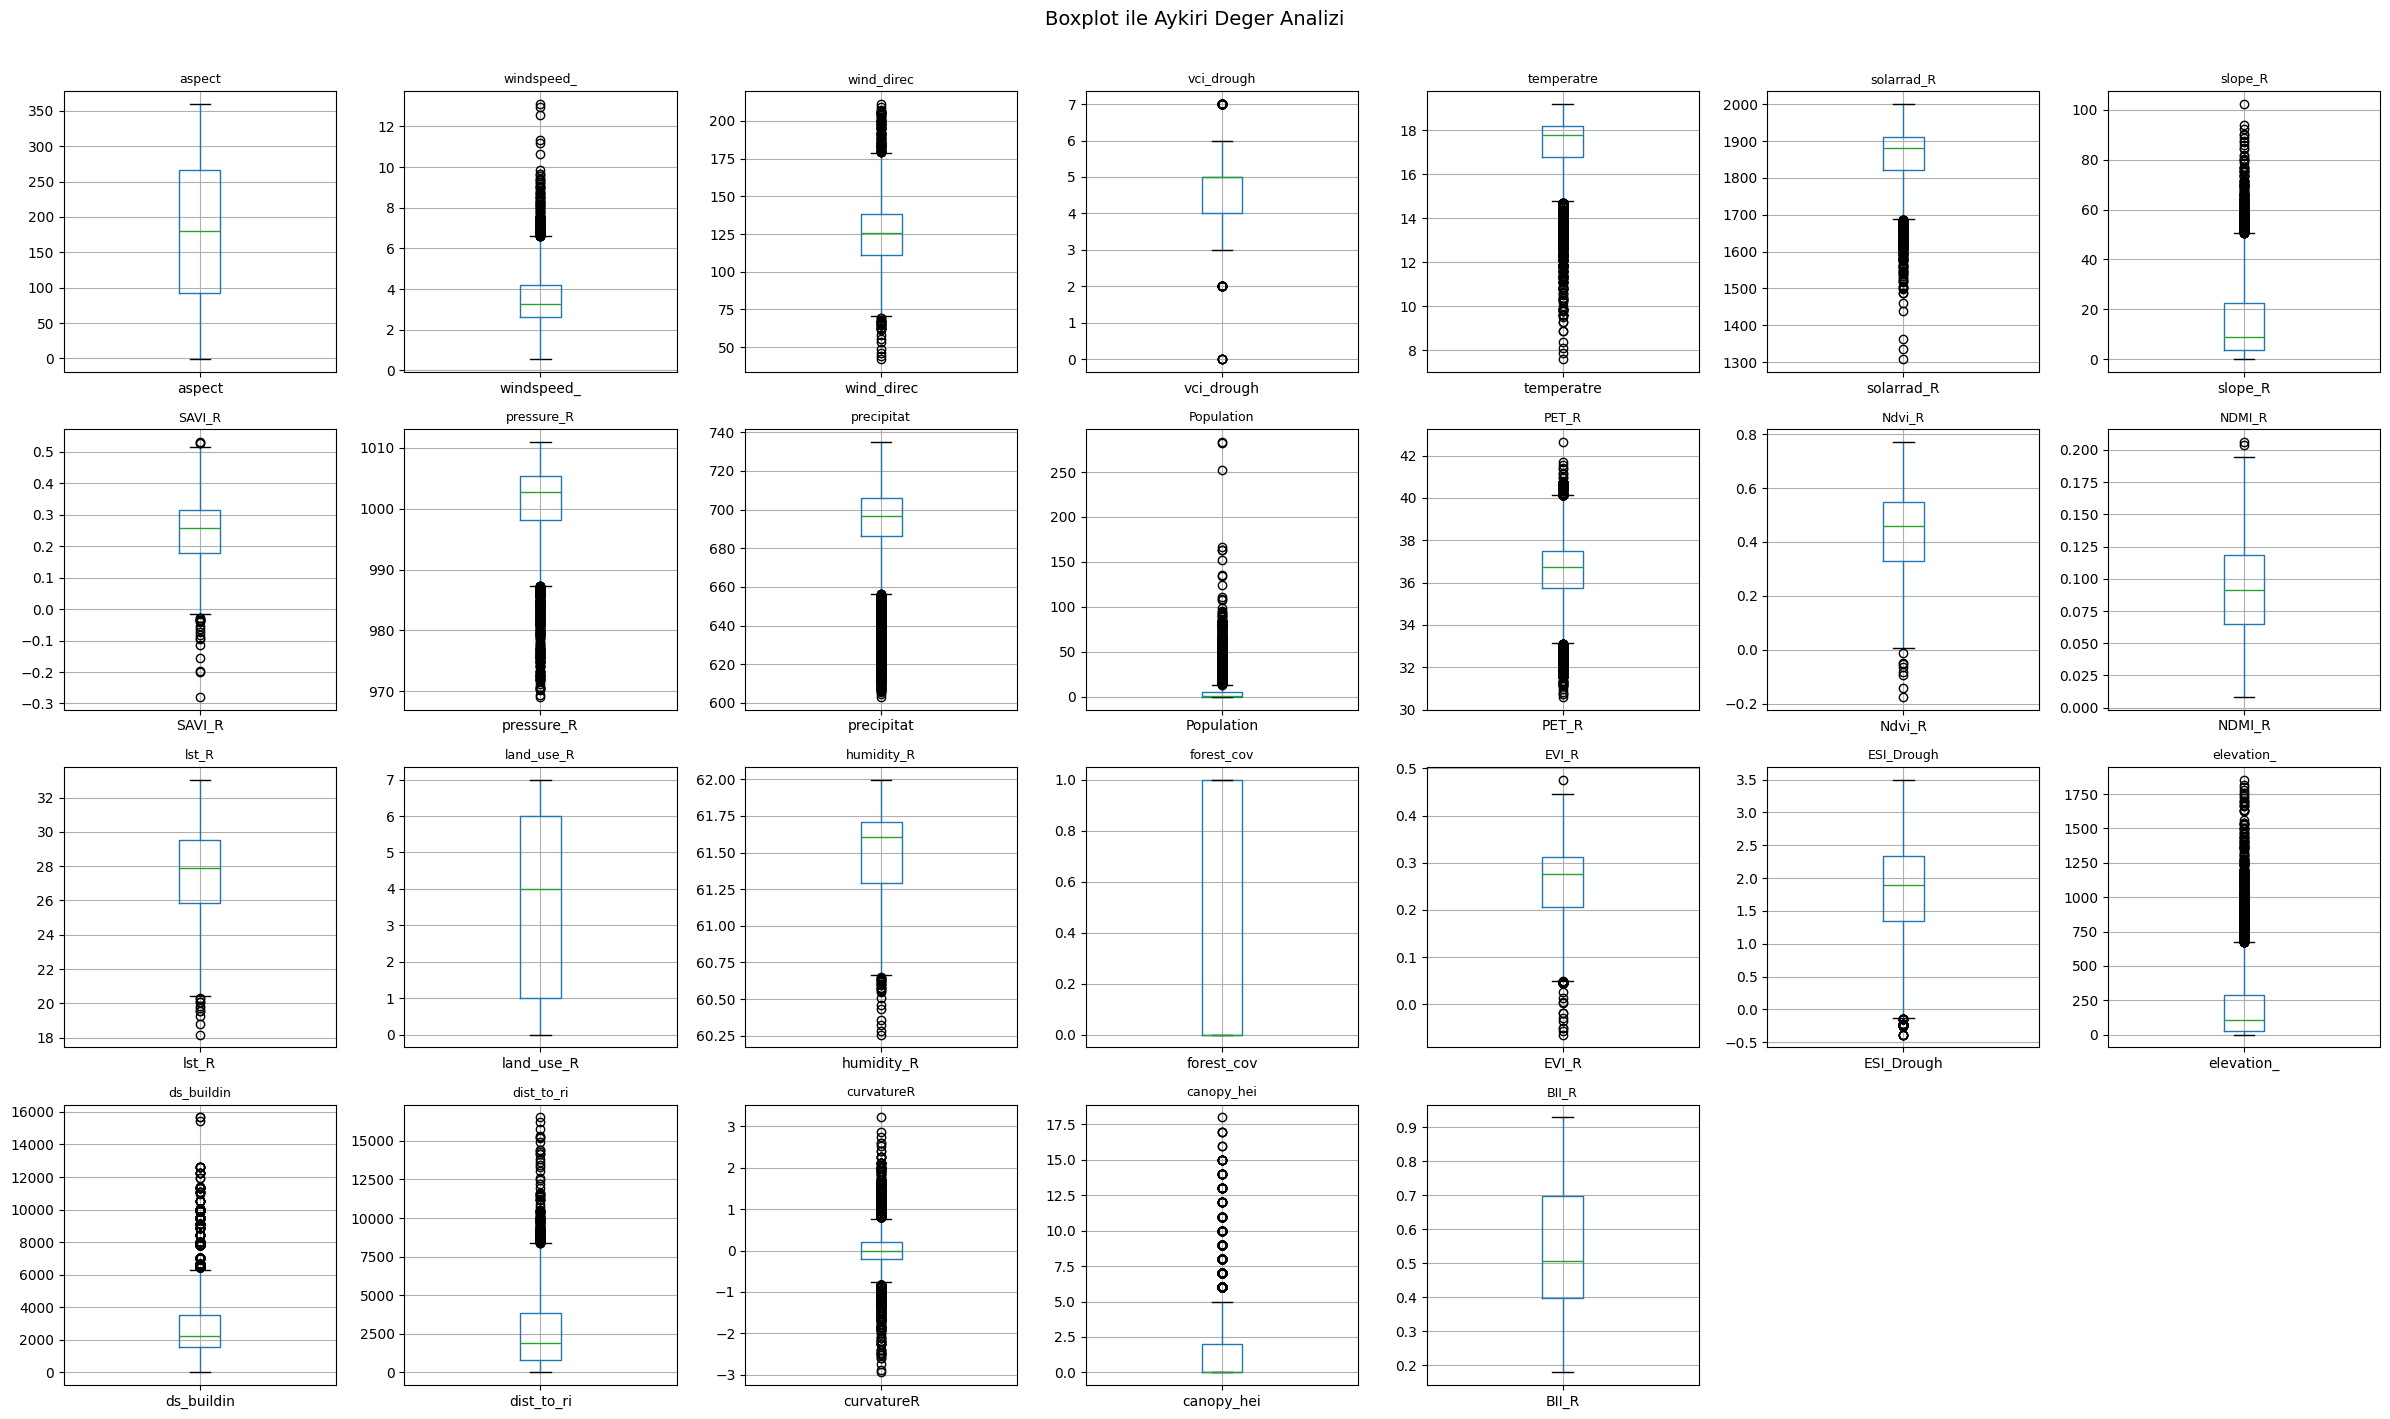

In [ ]:
# Boxplot ile aykiri deger gorsellestirmesi
analiz_sutunlar = df_temiz.select_dtypes(include=[np.number]).columns.drop('Target')

fig, axes = plt.subplots(4, 7, figsize=(24, 14))
axes = axes.flatten()

for i, col in enumerate(analiz_sutunlar):
    df_temiz.boxplot(column=col, ax=axes[i])
    axes[i].set_title(col, fontsize=9)

# kullanilmayan alt grafikleri gizle
for j in range(len(analiz_sutunlar), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplot ile Aykiri Deger Analizi', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# Z-score yontemi ile aykiri deger tespiti (esik: |z| > 3)
z_df = pd.DataFrame(np.abs(stats.zscore(df_temiz[analiz_sutunlar], nan_policy='omit')),
                     columns=analiz_sutunlar)
z_aykiri = (z_df > 3).sum()

print("=== Z-Score Yontemi (|z| > 3) ===")
print(z_aykiri[z_aykiri > 0].sort_values(ascending=False))
print(f"\nToplam aykiri deger: {(z_df > 3).sum().sum()}")

=== Z-Score Yontemi (|z| > 3) ===
Population    204
canopy_hei    170
curvatureR    149
elevation_    145
temperatre    139
pressure_R    124
slope_R       103
wind_direc     96
solarrad_R     92
precipitat     91
ds_buildin     86
windspeed_     72
humidity_R     36
vci_drough     31
dist_to_ri     28
PET_R          18
SAVI_R          8
EVI_R           8
lst_R           7
Ndvi_R          6
NDMI_R          2
dtype: int64

Toplam aykiri deger: 1615


In [ ]:
# IQR yontemi ile aykiri deger tespiti
print("=== IQR Yontemi ===")
iqr_aykiri = {}

for col in analiz_sutunlar:
    Q1 = df_temiz[col].quantile(0.25)
    Q3 = df_temiz[col].quantile(0.75)
    IQR = Q3 - Q1
    alt_sinir = Q1 - 1.5 * IQR
    ust_sinir = Q3 + 1.5 * IQR
    aykiri_count = ((df_temiz[col] < alt_sinir) | (df_temiz[col] > ust_sinir)).sum()
    if aykiri_count > 0:
        iqr_aykiri[col] = aykiri_count

iqr_sonuc = pd.Series(iqr_aykiri).sort_values(ascending=False)
print(iqr_sonuc)
print(f"\nToplam aykiri deger: {iqr_sonuc.sum()}")

=== IQR Yontemi ===
precipitat    876
curvatureR    771
dist_to_ri    728
PET_R         666
canopy_hei    640
elevation_    584
temperatre    578
ds_buildin    507
Population    477
pressure_R    281
slope_R       245
solarrad_R    234
windspeed_    155
EVI_R         146
wind_direc    112
vci_drough     86
ESI_Drough     48
humidity_R     27
SAVI_R         21
lst_R          11
Ndvi_R          8
NDMI_R          2
dtype: int64

Toplam aykiri deger: 7203


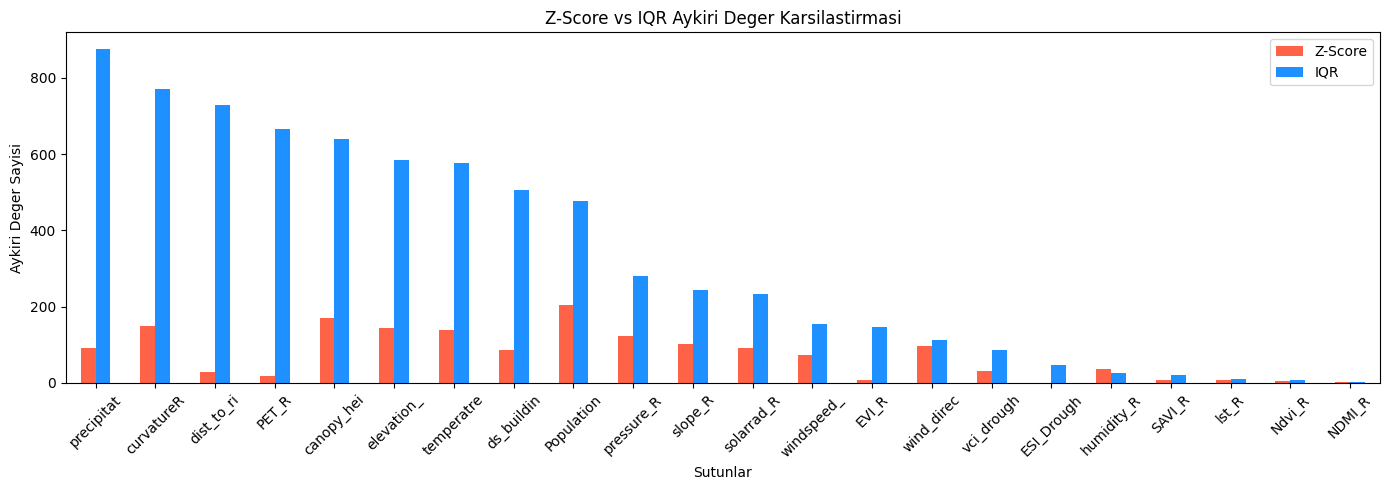

            Z-Score  IQR
precipitat       91  876
curvatureR      149  771
dist_to_ri       28  728
PET_R            18  666
canopy_hei      170  640
elevation_      145  584
temperatre      139  578
ds_buildin       86  507
Population      204  477
pressure_R      124  281
slope_R         103  245
solarrad_R       92  234
windspeed_       72  155
EVI_R             8  146
wind_direc       96  112
vci_drough       31   86
ESI_Drough        0   48
humidity_R       36   27
SAVI_R            8   21
lst_R             7   11
Ndvi_R            6    8
NDMI_R            2    2


In [ ]:
# yontem karsilastirmasi
karsilastirma = pd.DataFrame({
    'Z-Score': z_aykiri,
    'IQR': pd.Series(iqr_aykiri)
}).fillna(0).astype(int)

karsilastirma = karsilastirma[karsilastirma.sum(axis=1) > 0].sort_values('IQR', ascending=False)

karsilastirma.plot(kind='bar', figsize=(14, 5), color=['tomato', 'dodgerblue'])
plt.title('Z-Score vs IQR Aykiri Deger Karsilastirmasi')
plt.ylabel('Aykiri Deger Sayisi')
plt.xlabel('Sutunlar')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

print(karsilastirma)

## Soru 6 – Aykırı Değer Temizleme
**Yöntem**
* IQR ile aykırı değer temizleme yapılacak
* Alt sınırın altında kalan değerler alt sınıra, üst sınırın üstünde kalan değerler ise üst sınıra eşitlenmiştir. Temizleme işleminin başarısı, öncesi ve sonrası boxplot grafikleri çizdirilerek doğrulanmıştır

In [ ]:
# IQR yontemi ile aykiri degerleri temizleme
df_temizlenmis = df_temiz.copy()

for col in analiz_sutunlar:
    Q1 = df_temizlenmis[col].quantile(0.25)
    Q3 = df_temizlenmis[col].quantile(0.75)
    IQR = Q3 - Q1
    alt_sinir = Q1 - 1.5 * IQR
    ust_sinir = Q3 + 1.5 * IQR
    df_temizlenmis = df_temizlenmis[
        (df_temizlenmis[col] >= alt_sinir) & (df_temizlenmis[col] <= ust_sinir)
    ]

print("Temizleme oncesi:", df_temiz.shape)
print("Temizleme sonrasi:", df_temizlenmis.shape)
print(f"Kaldirilan satir sayisi: {df_temiz.shape[0] - df_temizlenmis.shape[0]}")

Temizleme oncesi: (7144, 27)
Temizleme sonrasi: (3296, 27)
Kaldirilan satir sayisi: 3848


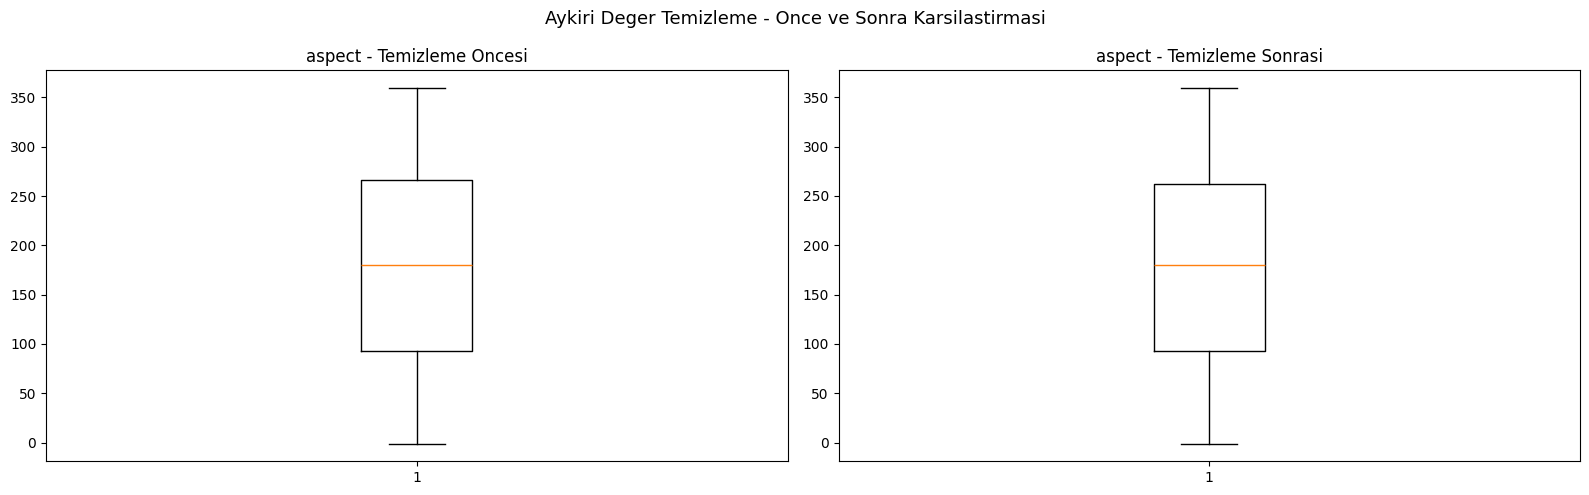


--- Temizleme Oncesi Istatistikler ---
          aspect  windspeed_  wind_direc  vci_drough  temperatre   solarrad_R  \
mean  179.713536    3.496124  124.450136    4.807391   17.205865  1857.435381   
std   101.471421    1.275932   19.094320    0.901798    1.526005    75.733941   
min    -1.000000    0.553982   42.048600    0.000000    7.600000  1307.960000   
max   359.433000   13.099400  211.206000    7.000000   19.200000  2000.470000   

         slope_R    SAVI_R   pressure_R  precipitat  ...  humidity_R  \
mean   14.907710  0.237160  1000.998309  689.649727  ...    61.50885   
std    14.984665  0.105867     6.468552   24.445420  ...     0.26720   
min     0.000000 -0.279034   969.085000  603.070000  ...    60.25740   
max   102.276000  0.532136  1010.980000  735.071000  ...    61.99760   

      forest_cov     EVI_R  ESI_Drough   elevation_    ds_buildin  \
mean    0.393477  0.251077    1.826074   217.235722   2508.910526   
std     0.488555  0.087326    0.819332   277.065932   2

In [ ]:
# once ve sonra karsilastirmasi
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ornek olarak iki sutunu gosterelim
ornek_sutun = analiz_sutunlar[0]

axes[0].boxplot(df_temiz[ornek_sutun].dropna())
axes[0].set_title(f'{ornek_sutun} - Temizleme Oncesi')

axes[1].boxplot(df_temizlenmis[ornek_sutun].dropna())
axes[1].set_title(f'{ornek_sutun} - Temizleme Sonrasi')

plt.suptitle('Aykiri Deger Temizleme - Once ve Sonra Karsilastirmasi', fontsize=13)
plt.tight_layout()
plt.show()

# istatistiksel karsilastirma
print("\n--- Temizleme Oncesi Istatistikler ---")
print(df_temiz[analiz_sutunlar].describe().loc[['mean', 'std', 'min', 'max']])
print("\n--- Temizleme Sonrasi Istatistikler ---")
print(df_temizlenmis[analiz_sutunlar].describe().loc[['mean', 'std', 'min', 'max']])

## Soru 7 – NumPy ile İstatistiksel Analiz
Aykırı değerlerden arındırılmış temiz veri seti üzerinden, sıcaklık (`temperatre`) ve rüzgar hızı (`windspeed_`) değişkenleri seçilmiş; temel betimsel istatistikler (ortalama, standart sapma, minimum, maksimum) NumPy kütüphanesine ait fonksiyonlar ile hesaplanmıştır

In [ ]:
# NumPy ile en az iki degisken uzerinde istatistiksel analiz
secilen_degiskenler = ['temperatre', 'humidity_R', 'windspeed_']

for col in secilen_degiskenler:
    veri = df_temizlenmis[col].values
    print(f"=== {col} ===")
    print(f"  Ortalama (mean)  : {np.mean(veri):.4f}")
    print(f"  Standart sapma   : {np.std(veri):.4f}")
    print(f"  Minimum          : {np.min(veri):.4f}")
    print(f"  Maksimum         : {np.max(veri):.4f}")
    print()

=== temperatre ===
  Ortalama (mean)  : 17.9111
  Standart sapma   : 0.6073
  Minimum          : 15.3000
  Maksimum         : 19.1000

=== humidity_R ===
  Ortalama (mean)  : 61.4603
  Standart sapma   : 0.2568
  Minimum          : 60.6813
  Maksimum         : 61.9703

=== windspeed_ ===
  Ortalama (mean)  : 3.5359
  Standart sapma   : 0.9614
  Minimum          : 0.6633
  Maksimum         : 6.5535



## Soru 8 – Filtreleme ile Sınıf Dağılımı
`Target` (Hedef) değişkeni veri setinin bağımlı değişkenidir. Bu sütun filtrelenerek veri setinde yer alan sınıfların toplam kayıt sayıları ve yüzdesel oranları tespit edilmiştir. Bu adım, sınıf dengesizliği (class imbalance) olup olmadığını anlamak için önemlidir.

In [ ]:
# Target sutununa gore filtreleme
sinif_dagilimi = df_temizlenmis['Target'].value_counts()
sinif_yuzde = df_temizlenmis['Target'].value_counts(normalize=True) * 100

sinif_tablo = pd.DataFrame({
    'Kayit Sayisi': sinif_dagilimi,
    'Yuzde Orani (%)': sinif_yuzde.round(2)
})

print("=== Target Sinif Dagilimi ===")
print(sinif_tablo)
print(f"\nToplam kayit: {sinif_dagilimi.sum()}")

# her sinif icin ayri filtreleme
for sinif in sorted(df_temizlenmis['Target'].unique()):
    df_filtre = df_temizlenmis[df_temizlenmis['Target'] == sinif]
    print(f"\nTarget = {sinif}: {len(df_filtre)} kayit ({len(df_filtre)/len(df_temizlenmis)*100:.2f}%)")

=== Target Sinif Dagilimi ===
        Kayit Sayisi  Yuzde Orani (%)
Target                               
1               2324            70.51
0                972            29.49

Toplam kayit: 3296

Target = 0: 972 kayit (29.49%)

Target = 1: 2324 kayit (70.51%)


## Soru 9 – Veri Görselleştirme
Değişkenlerin birbirleriyle olan doğrusal ilişkilerini ve yönlerini analiz etmek amacıyla Korelasyon Matrisi hesaplanmıştır.

Görselleştirmeyi kolaylaştırmak ve yüksek korelasyonlu ilişkileri (multicollinearity) tespit edebilmek için veriler renk skalasına dayalı bir ısı haritası (Heatmap) üzerinde sunulmuştur

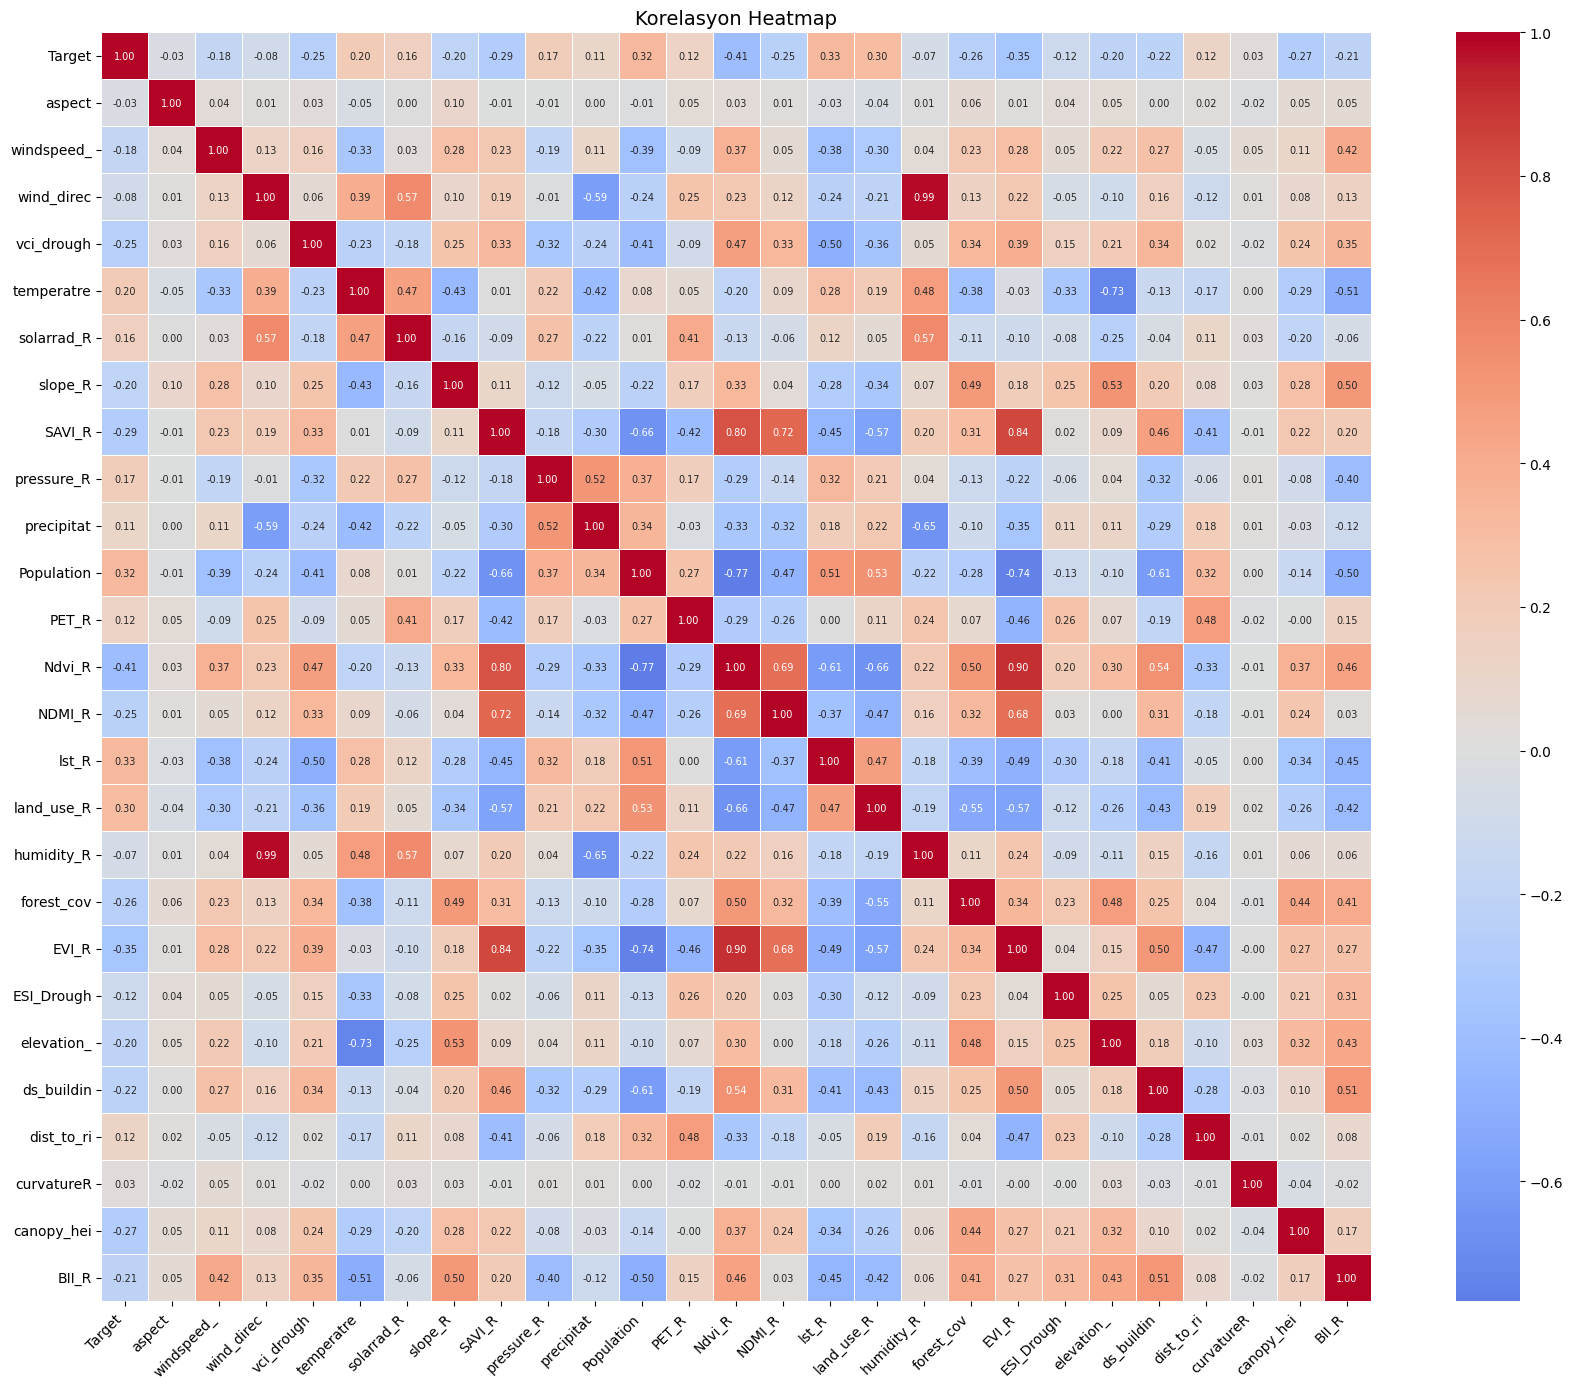

In [ ]:
# korelasyon heatmap
plt.figure(figsize=(18, 14))

korelasyon = df_temizlenmis.select_dtypes(include=[np.number]).corr()

sns.heatmap(korelasyon, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, square=True, annot_kws={'size': 7})

plt.title('Korelasyon Heatmap', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()